### Project 3: House Price Prediction using Machine Learning with Python (ML)
# Chihat GetHub Linked IN 

في هذا المشروع نحاولوا نديروا بالمودل 
### Linear regression
### SVM (Suport Vector Machine)

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns
from sklearn.model_selection import train_test_split
from xgboost import XGBRegressor

In [75]:
data = pd.read_csv("HousingData.csv")

سعر المنزل راه بالألاف

In [76]:
data.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,NaN,36.2


In [77]:
data.shape

(506, 14)

In [78]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     486 non-null    float64
 1   ZN       486 non-null    float64
 2   INDUS    486 non-null    float64
 3   CHAS     486 non-null    float64
 4   NOX      506 non-null    float64
 5   RM       506 non-null    float64
 6   AGE      486 non-null    float64
 7   DIS      506 non-null    float64
 8   RAD      506 non-null    int64  
 9   TAX      506 non-null    int64  
 10  PTRATIO  506 non-null    float64
 11  B        506 non-null    float64
 12  LSTAT    486 non-null    float64
 13  MEDV     506 non-null    float64
dtypes: float64(12), int64(2)
memory usage: 55.5 KB


there exists a missing value so must be solve this problem

In [79]:
data.describe()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
count,486.000000,486.000000,486.000000,486.000000,506.000000,506.000000,486.000000,506.000000,506.000000,506.000000,506.000000,506.000000,486.000000,506.000000
mean,3.611874,11.211934,11.083992,0.069959,0.554695,6.284634,68.518519,3.795043,9.549407,408.237154,18.455534,356.674032,12.715432,22.532806
std,8.720192,23.388876,6.835896,0.255340,0.115878,0.702617,27.999513,2.105710,8.707259,168.537116,2.164946,91.294864,7.155871,9.197104
min,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,0.320000,1.730000,5.000000
25%,0.081900,0.000000,5.190000,0.000000,0.449000,5.885500,45.175000,2.100175,4.000000,279.000000,17.400000,375.377500,7.125000,17.025000
50%,0.253715,0.000000,9.690000,0.000000,0.538000,6.208500,76.800000,3.207450,5.000000,330.000000,19.050000,391.440000,11.430000,21.200000
75%,3.560263,12.500000,18.100000,0.000000,0.624000,6.623500,93.975000,5.188425,24.000000,666.000000,20.200000,396.225000,16.955000,25.000000
max,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,396.900000,37.970000,50.000000


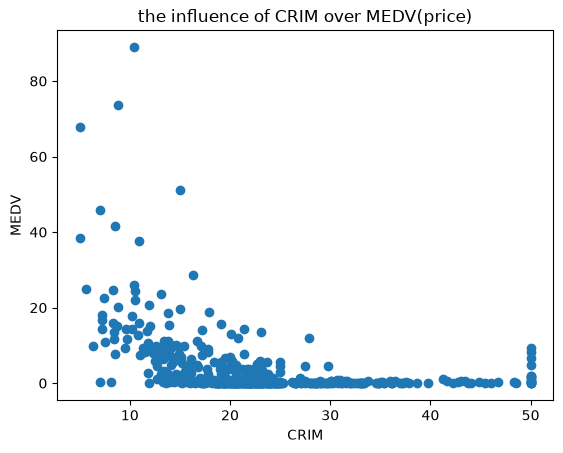

In [80]:
plt.scatter(y=data["CRIM"], x=data["MEDV"])
plt.xlabel("CRIM")
plt.ylabel("MEDV")
plt.title("the influence of CRIM over MEDV(price)")
plt.show()

we see when CRIM is increase the price is decrease (opposite relation !!)

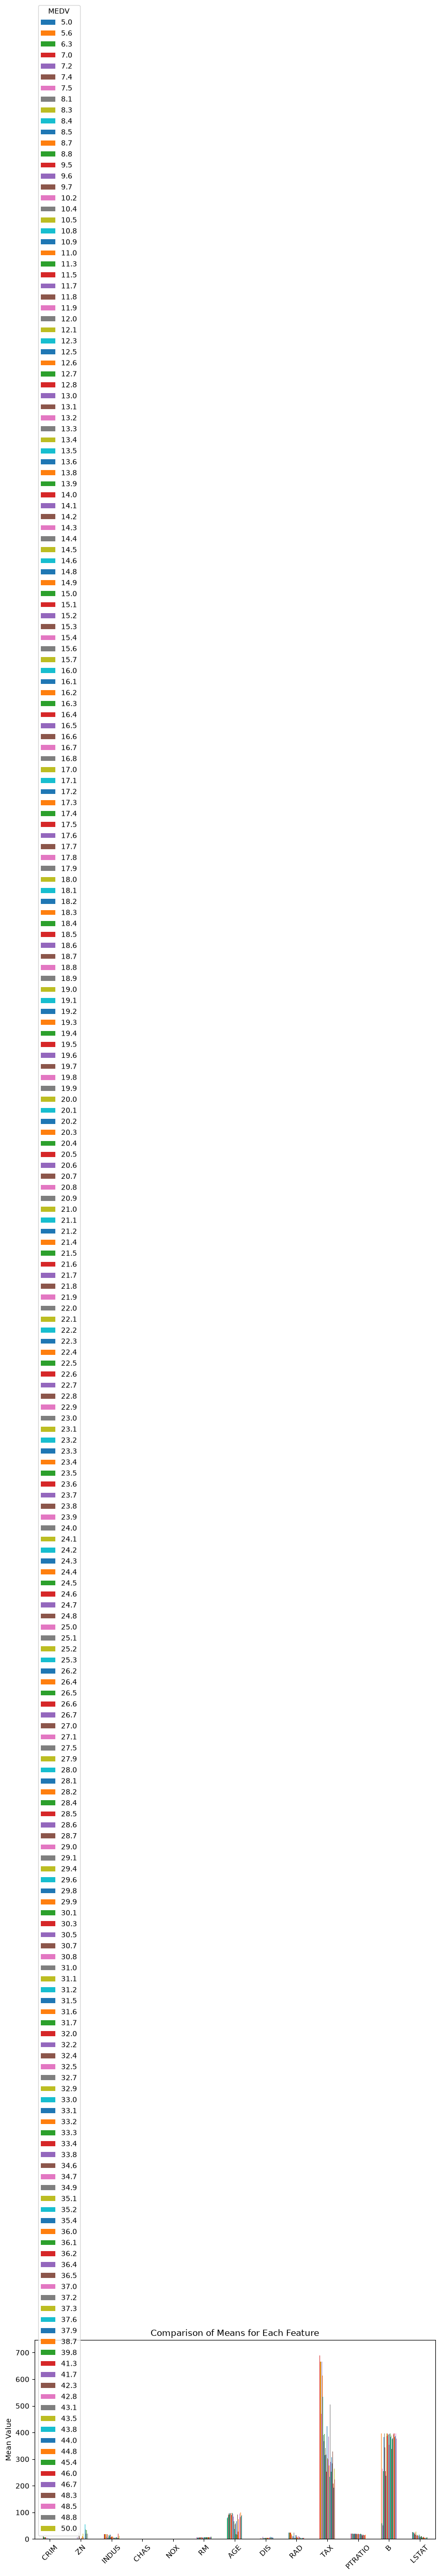

In [81]:
data.groupby('MEDV').mean().T.plot(kind='bar', figsize=(10, 5))

plt.title('Comparison of Means for Each Feature')
plt.ylabel('Mean Value')
plt.xticks(rotation=45)
plt.show()

there is a outliers in our data !! we will see

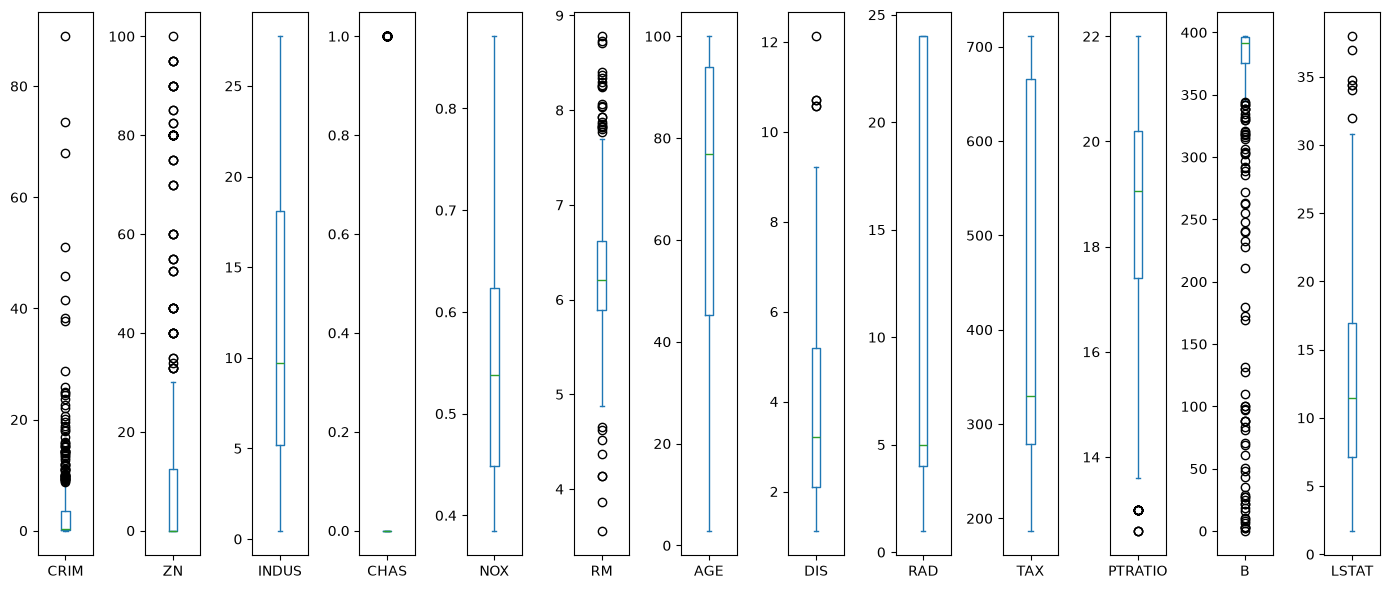

In [82]:
data.drop(columns=['MEDV']).plot(kind='box', subplots=True, figsize=(14, 6))

plt.tight_layout()
plt.show()

في CRIM AND B توجد الكثير من القيم الشاذة نجربو طريقة الLOGARITHM

In [83]:
# تطبيق التحويل اللوغاريتمي للأعمدة ذات التشتت العالي جداً
data['CRIM_log'] = np.log1p(data['CRIM'])


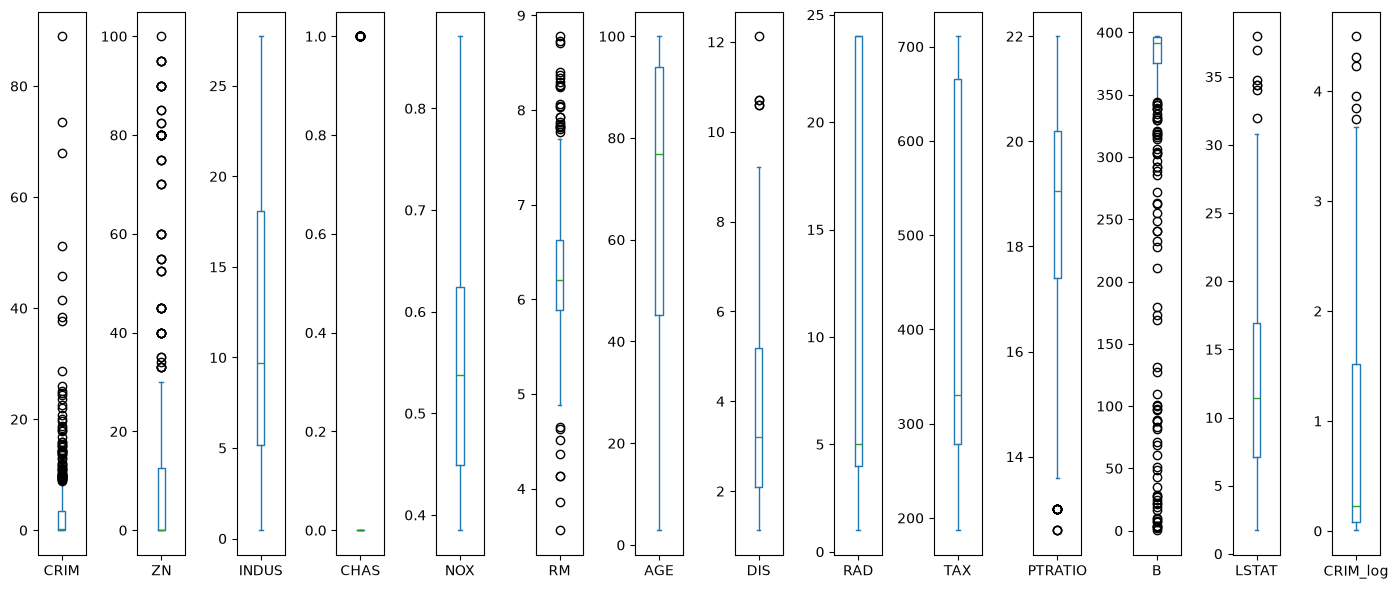

In [84]:
data.drop(columns=['MEDV']).plot(kind='box', subplots=True, figsize=(14, 6))

plt.tight_layout()
plt.show()

In [85]:
data.isnull().sum()

CRIM        20
ZN          20
INDUS       20
CHAS        20
NOX          0
RM           0
AGE         20
DIS          0
RAD          0
TAX          0
PTRATIO      0
B            0
LSTAT       20
MEDV         0
CRIM_log    20
dtype: int64

In [86]:
cols_with_nan = ['CRIM', 'ZN', 'INDUS', 'CHAS', 'AGE', 'LSTAT']

for col in cols_with_nan:
    data[col] = data[col].fillna(data[col].median())


data['CRIM_log'] = np.log1p(data['CRIM'])

In [87]:
data.isnull().sum()

CRIM        0
ZN          0
INDUS       0
CHAS        0
NOX         0
RM          0
AGE         0
DIS         0
RAD         0
TAX         0
PTRATIO     0
B           0
LSTAT       0
MEDV        0
CRIM_log    0
dtype: int64

In [88]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 15 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   CRIM      506 non-null    float64
 1   ZN        506 non-null    float64
 2   INDUS     506 non-null    float64
 3   CHAS      506 non-null    float64
 4   NOX       506 non-null    float64
 5   RM        506 non-null    float64
 6   AGE       506 non-null    float64
 7   DIS       506 non-null    float64
 8   RAD       506 non-null    int64  
 9   TAX       506 non-null    int64  
 10  PTRATIO   506 non-null    float64
 11  B         506 non-null    float64
 12  LSTAT     506 non-null    float64
 13  MEDV      506 non-null    float64
 14  CRIM_log  506 non-null    float64
dtypes: float64(13), int64(2)
memory usage: 59.4 KB


In [89]:
data.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV,CRIM_log
0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0,0.006300
1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6,0.026944
2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7,0.026924
3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4,0.031857
4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,11.43,36.2,0.066770


In [90]:
correletion = data.corr()

<Axes: >

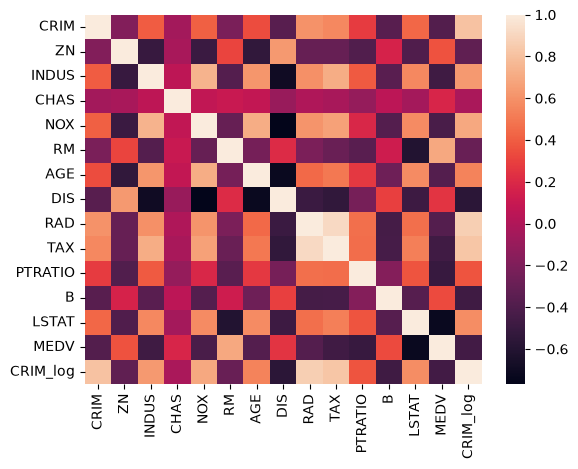

In [91]:
sns.heatmap(correletion)

In [92]:
Y = data["MEDV"]
X = data.drop(columns="MEDV")

In [93]:
X = X.drop(columns="CRIM")
X = X.drop(columns="B")

In [94]:
Y.head()

0    24.0
1    21.6
2    34.7
3    33.4
4    36.2
Name: MEDV, dtype: float64

In [95]:
X.head()

,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,CRIM_log
0,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1,296,15.3,4.98,0.006300
1,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2,242,17.8,9.14,0.026944
2,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2,242,17.8,4.03,0.026924
3,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3,222,18.7,2.94,0.031857
4,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3,222,18.7,11.43,0.066770


In [99]:
X.shape

(506, 12)

In [100]:
Y.shape

(506,)

In [103]:
X_train,X_test,Y_train,Y_test = train_test_split(X, Y, test_size=0.1, random_state=2)

### 🚀 XGBoost Regressor Overview

**XGBoost (eXtreme Gradient Boosting)** is an optimized, high-performance machine learning algorithm designed for tabular regression tasks. It builds an ensemble of decision trees sequentially using a **Gradient Boosting** framework.

* **Sequential Learning:** Each new decision tree is built to correct the errors (residuals) made by the previous trees.
* **Overfitting Control:** Built-in $L_1$ (Lasso) and $L_2$ (Ridge) regularization penalties prevent the model from memorizing noise.
* **Missing Value Handling:** Automatically learns the optimal split direction for missing data (`NaN` values).
* **Speed & Scale:** Parallel computing allows rapid training on large datasets without requiring prior feature scaling.

### 🚀 نبذة عن نموذج XGBoost Regressor

يُعد **XGBoost** واحدًا من أقوى وأسرع خوارزميات تعلم الآلة المخصصة لمشاكل الانحدار (Regression) والبيانات الجدولية. يعتمد المودل على بناء مجموعة متتالية من أشجار القرار باستراتيجية **Gradient Boosting**.

* **التعلم المتتابع:** تُبنى كل شجرة قرار جديدة خصيصًا لتصحيح الأخطاء (Residuals) التي ارتكبتها الأشجار التي سبقتها.
* **الحماية من الحفظ (Overfitting):** يحتوي على أدوات انتظام مدمجة ($L_1$ و $L_2$) تمنع النموذج من حفظ البيانات المزعجة.
* **التعامل الذاتي مع القيم المفقودة:** يكتشف تلقائيًا المسار الأمثل للتعامل مع القيم المفقودة (`NaN`) دون التوقف.
* **السرعة العالية:** يستغل معالج الكمبيوتر للتدريب بالتوازي، ولا يتأثر باختلاف مقاييس البيانات (لا يحتاج لـ Scaling بالضرورة).

In [104]:
model = XGBRegressor()

In [113]:
model.fit(X_train, Y_train)

train_data_predected = model.predict(X_train)

In [119]:
test_data_predected = model.predict(X_test)

THE ACCURACY OF OUR MODEL ????

R Squared Error

In [ ]:
from sklearn.metrics import r2_score

train_r2 = r2_score(Y_train, train_data_predected)
test_r2 = r2_score(Y_test, test_data_predected)

print(f"R2 Score (Train): {train_r2:.4f}")
print(f"R2 Score (Test): {test_r2:.4f}")

R2 Score (Train): 1.0000
R2 Score (Test): 0.8867


88%

مقدار الخطأ بالدولار 

In [123]:
from sklearn.metrics import mean_absolute_error

train_mae = mean_absolute_error(Y_train, train_data_predected)
test_mae = mean_absolute_error(Y_test, test_data_predected)

print(f"MAE (Train): {train_mae:.4f}")
print(f"MAE (Test): {test_mae:.4f}")

MAE (Train): 0.0224
MAE (Test): 2.3182


أي خاصية كان لها تأثير على السعر ؟؟؟

<Figure size 1000x600 with 0 Axes>

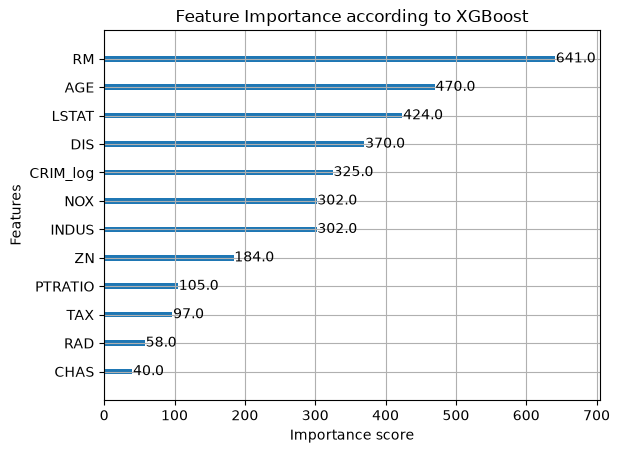

In [125]:
from xgboost import plot_importance

plt.figure(figsize=(10, 6))
plot_importance(model, importance_type='weight')
plt.title('Feature Importance according to XGBoost')
plt.show()

مقارنة الحقيقي بالمتوقع

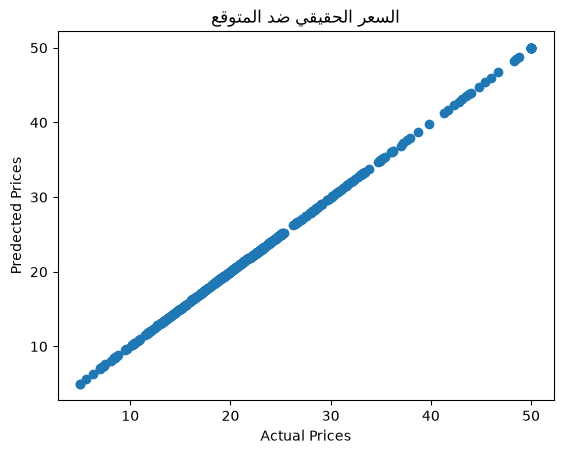

In [126]:
plt.scatter(Y_train, train_data_predected)
plt.xlabel("Actual Prices")
plt.ylabel("Predected Prices")
plt.title("السعر الحقيقي ضد المتوقع")
plt.show()

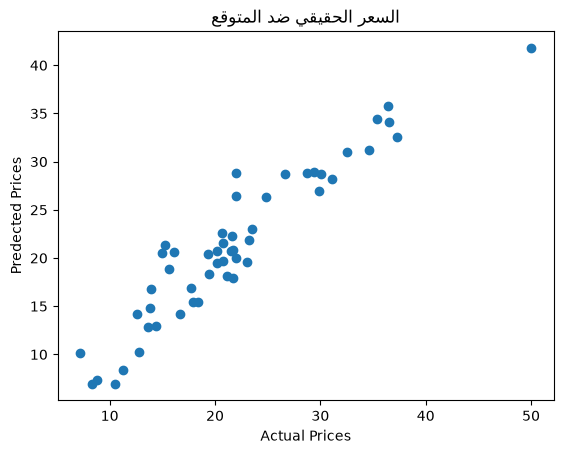

In [127]:
plt.scatter(Y_test, test_data_predected)
plt.xlabel("Actual Prices")
plt.ylabel("Predected Prices")
plt.title("السعر الحقيقي ضد المتوقع")
plt.show()